# Informer — next-day / 5-day stock return forecasting

**Stock Transformers** · Deep Learning final project · Khush Agrawal, Yashvi Mehta, Ghruank Kothare

Paper in this folder: *Informer: Beyond Efficient Transformer for Long Sequence Time-Series Forecasting* (Zhou et al., AAAI 2021, best paper).

### Architecture
```
Encoder input  : x (96 × 87)  ─► Conv1d token emb + positional + temporal(month, day, weekday) + asset emb
                 [ ProbSparse self-attention block ─► distilling Conv1d+ELU+MaxPool(÷2) ] × (e_layers−1) ─► last block
Decoder input  : last 48 days of x (start token) ‖ 5 zero placeholders, same embeddings
                 masked ProbSparse self-attention ─► cross-attention to encoder ─► FFN
                 ─► Linear ─► 5 outputs (generative-style: all horizons in one forward pass)
```
* **ProbSparse attention:** only the top-u = c·ln L "active" queries (largest max–mean score gap, estimated on a random key sample) get full attention; "lazy" queries receive mean(V). Cost O(L log L) instead of O(L²).
* **Self-attention distilling** halves the sequence between encoder blocks, keeping dominant features and cutting memory.
* **Generative decoder** predicts the whole horizon at once — no error accumulation from step-by-step decoding.



## 0 · Setup
On Colab: upload the project bundle, `tar xzf` it into `/content/proj`, and run all. Locally: run from this folder with the project's virtualenv. Nothing is downloaded at runtime — the feature-engineered dataset is `data/dataset.npz` (built by `scripts/prepare_dataset.py`).

In [1]:
import os, sys, json, glob
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt

# ---- locate the project root (works locally and on Colab after unpacking the bundle into /content/proj)
ROOT = os.path.abspath("..") if os.path.exists("../src/stockdl") else "/content/proj"
sys.path.insert(0, os.path.join(ROOT, "src"))
from stockdl.data import load_panel, feature_group
from stockdl.train import fit, predict, build_model
from stockdl.metrics import evaluate, naive_metrics, breakdown

MODEL = "informer"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TRAIN = False          # True = retrain the selected configuration here (GPU recommended, ~5-30 min)
RESULTS = os.environ.get("STOCKDL_RESULTS", os.path.join(ROOT, "results"))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "font.size": 10})
COLORS = {"lstm": "#2a78d6", "transformer": "#eb6834", "informer": "#1baf7a", "ridge": "#898781", "naive": "#898781"}
print("root:", ROOT, "| device:", DEVICE)

root: /home/ghruank/college/sem7/dl/project/finalproject | device: cpu


## 1 · Data
49 assets (25 Indian large caps, 10 volatile Indian mid/small caps, 8 US mega caps, 6 commodities), daily bars 2005 → Nov 2026. 87 engineered features; per-asset scaling fitted on the training period only.

assets: 49  features: 87  horizon: 5 days
train windows:  163802   period: ['2007-01-01', '2022-01-01']
val   windows:   23990   period: ['2022-01-01', '2024-01-01']
test  windows:   34700   period: ['2024-01-01', '2026-11-19']


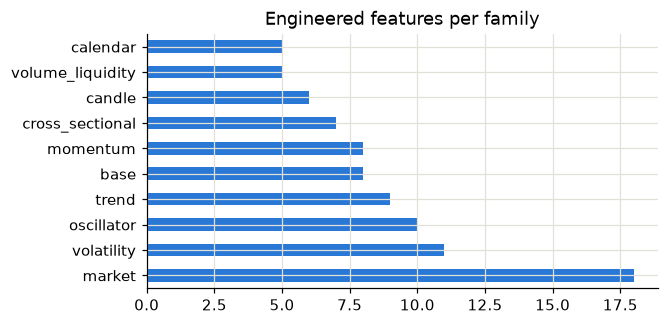

In [2]:
panel = load_panel(os.path.join(ROOT, "data", "dataset.npz"), "full", lookback=96, device="cpu")
meta = panel.meta
print(f"assets: {len(meta['tickers'])}  features: {panel.X.shape[1]}  horizon: {panel.horizon} days")
for s in ("train", "val", "test"):
    print(f"{s:5s} windows: {len(panel.ends[s]):7d}   period: {meta['splits'][s]}")
groups = pd.Series([feature_group(n) for n in meta["features_full"]]).value_counts()
groups.plot.barh(color="#2a78d6", figsize=(6, 3), title="Engineered features per family"); plt.show()

## 2 · Model & hyper-parameter search
Configurations were scored on 2022–2023 validation loss only; the test period was never used for selection.

In [3]:
rows = [json.loads(l) for l in open(os.path.join(RESULTS, MODEL, "runs.jsonl"))]
search = [r for r in rows if r["phase"] == "search"]
best = min(search, key=lambda r: r["best_val_loss"])
cfg = best["cfg"]
print("hyper-parameter search (validation 2022-2023):")
display(pd.DataFrame([{**r["cfg"], "val_loss": r["best_val_loss"], "val_DA_%": r["val"]["DA_%"], "epochs": r["epochs_run"],
                       "params": r["n_params"]} for r in search]).round(4))
print("selected:", cfg)
net = build_model(MODEL, panel, cfg)
print(net)
print(f"trainable parameters: {sum(p.numel() for p in net.parameters() if p.requires_grad):,}")

hyper-parameter search (validation 2022-2023):


,d_model,e_layers,dropout,lr,factor,n_heads,d_ff,attn,val_loss,val_DA_%,epochs,params,patience
0,64,2,0.1,0.0003,5,4,256,prob,1.1849,51.5760,5,216801,NaN
1,64,3,0.1,0.0003,5,4,256,prob,1.1842,51.8495,4,279265,3.0
2,64,3,0.3,0.0003,5,4,256,prob,1.1837,51.9926,4,279265,3.0


selected: {'d_model': 64, 'e_layers': 3, 'dropout': 0.3, 'lr': 0.0003, 'factor': 5, 'n_heads': 4, 'd_ff': 256, 'attn': 'prob', 'patience': 3}
InformerForecaster(
  (enc_embedding): DataEmbedding(
    (value): TokenEmbedding(
      (conv): Conv1d(87, 64, kernel_size=(3,), stride=(1,), padding=(1,), padding_mode=circular)
    )
    (position): PositionalEmbedding()
    (temporal): TemporalEmbedding(
      (month): FixedEmbedding(
        (emb): Embedding(13, 64)
      )
      (day): FixedEmbedding(
        (emb): Embedding(32, 64)
      )
      (weekday): FixedEmbedding(
        (emb): Embedding(7, 64)
      )
    )
    (asset): Sequential(
      (0): Embedding(49, 16)
      (1): Linear(in_features=16, out_features=64, bias=True)
    )
    (drop): Dropout(p=0.3, inplace=False)
  )
  (dec_embedding): DataEmbedding(
    (value): TokenEmbedding(
      (conv): Conv1d(87, 64, kernel_size=(3,), stride=(1,), padding=(1,), padding_mode=circular)
    )
    (position): PositionalEmbedding()
    (t

## 3 · Training
AdamW, 1-epoch warm-up + cosine decay, gradient clipping 1.0, mixed precision on GPU, early stopping on validation loss.

TRAIN=False -> using the runs trained on the Colab T4 GPU (results/informer/runs.jsonl)


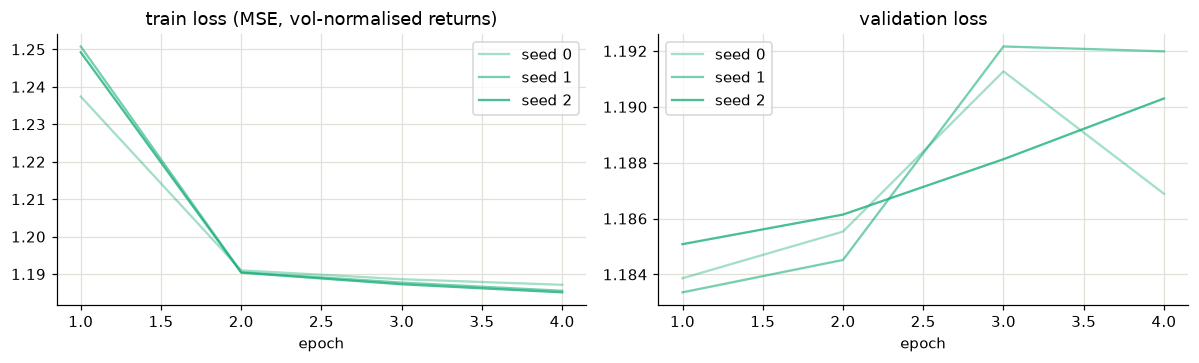

In [4]:
if TRAIN:
    p = load_panel(os.path.join(ROOT, "data", "dataset.npz"), "full", 96, DEVICE)
    net, info = fit(MODEL, p, cfg, seed=0)
    pred = predict(net, p, "test")
    met, _ = evaluate(pred, p.ends["test"], p)
    print(pd.Series(met).round(4))
else:
    print("TRAIN=False -> using the runs trained on the Colab T4 GPU (results/%s/runs.jsonl)" % MODEL)

# learning curves of the selected configuration's final runs
fin = [r for r in rows if r["phase"] == "final" and r["features"] == "full"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for r in fin:
    h = pd.DataFrame(r["history"])
    ax[0].plot(h.epoch + 1, h.train_loss, color=COLORS[MODEL], alpha=.4 + .2 * r["seed"], label=f"seed {r['seed']}")
    ax[1].plot(h.epoch + 1, h.val_loss, color=COLORS[MODEL], alpha=.4 + .2 * r["seed"], label=f"seed {r['seed']}")
ax[0].set_title("train loss (MSE, vol-normalised returns)"); ax[1].set_title("validation loss")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

## 4 · Test-set evaluation (Jan 2024 – Nov 2026)
* **DA** directional accuracy · **IC** daily cross-sectional rank correlation · **R²oos** vs. the zero-return forecast
* **MAPE** next-day price error (compare with the naive random walk) · **Sharpe_LS** market-neutral long/short (gross) · **Sharpe_dir_net** sign strategy after 10 bps costs
* *base* = 8 basic price/volume features (stationary) · *full* = 87 engineered features

In [5]:
KEY = ["DA_%", "DA_xs_%", "IC", "R2_oos_%", "MAPE_%", "Sharpe_LS", "Sharpe_dir_net", "DA_5d_%"]
tab = []
for phase, ens_phase, fs, label in [("final", "ensemble", "base", "base"),
                                    ("final", "ensemble", "full", "full"), ("xs", "ensemble_xs", "base", "market-neutral base"),
                                    ("xs", "ensemble_xs", "full", "market-neutral full")]:
    rr = [r for r in rows if r["phase"] == phase and r["features"] == fs]
    if rr:
        d = pd.DataFrame([r["test"] for r in rr]).reindex(columns=KEY)
        tab.append(pd.Series({k: f"{d[k].mean():.3f} ± {d[k].std():.3f}" if len(d) > 1 else f"{d[k].mean():.3f}" for k in KEY}, name=f"{label} ({len(rr)} seeds)"))
    e = [r for r in rows if r["phase"] == ens_phase and r["features"] == fs]
    if e:
        tab.append(pd.Series({k: f"{e[0]['test'].get(k, float('nan')):.3f}" for k in KEY}, name=f"{label} seed-ensemble"))
base_rows = [json.loads(l) for l in open(os.path.join(RESULTS, "baselines", "runs.jsonl"))]
for r in base_rows:
    if "key" in r and not r["key"].startswith("baseline"):
        continue
    tab.append(pd.Series({k: ("—" if r["test"].get(k) is None or (isinstance(r["test"][k], float) and np.isnan(r["test"][k])) else f"{r['test'][k]:.3f}") for k in KEY}, name=f"baseline: {r['model']}"))
print("TEST 2024-01 .. 2026-11 (out-of-sample)")
display(pd.DataFrame(tab))

TEST 2024-01 .. 2026-11 (out-of-sample)


,DA_%,DA_xs_%,IC,R2_oos_%,MAPE_%,Sharpe_LS,Sharpe_dir_net,DA_5d_%
base (3 seeds),50.800 ± 0.143,50.166 ± 0.373,-0.001 ± 0.005,0.032 ± 0.045,1.378 ± 0.000,0.064 ± 0.549,0.711 ± 0.226,51.984 ± 0.077
base seed-ensemble,50.952,50.416,-0.003,0.067,1.378,-0.154,0.962,51.946
full (3 seeds),50.265 ± 0.680,49.924 ± 0.323,-0.004 ± 0.001,-0.073 ± 0.137,1.378 ± 0.000,-0.245 ± 0.105,-0.433 ± 1.207,51.121 ± 1.428
full seed-ensemble,50.234,49.883,-0.008,-0.003,1.377,-0.664,-0.027,51.280
market-neutral full (3 seeds),49.529 ± 0.428,49.754 ± 0.118,-0.006 ± 0.001,-0.258 ± 0.219,1.379 ± 0.002,-0.076 ± 0.227,-1.448 ± 0.377,49.580 ± 1.332
market-neutral full seed-ensemble,49.109,49.618,-0.005,-0.190,1.378,0.058,-1.418,48.740
baseline: naive,—,—,0.000,0.000,1.376,0.000,0.000,—
baseline: ridge,50.365,50.641,0.022,-0.609,1.382,1.746,-0.335,51.015
baseline: ridge_xs,50.310,50.664,0.030,-0.464,1.381,1.851,-1.116,48.959


## 5 · What the forecasts look like

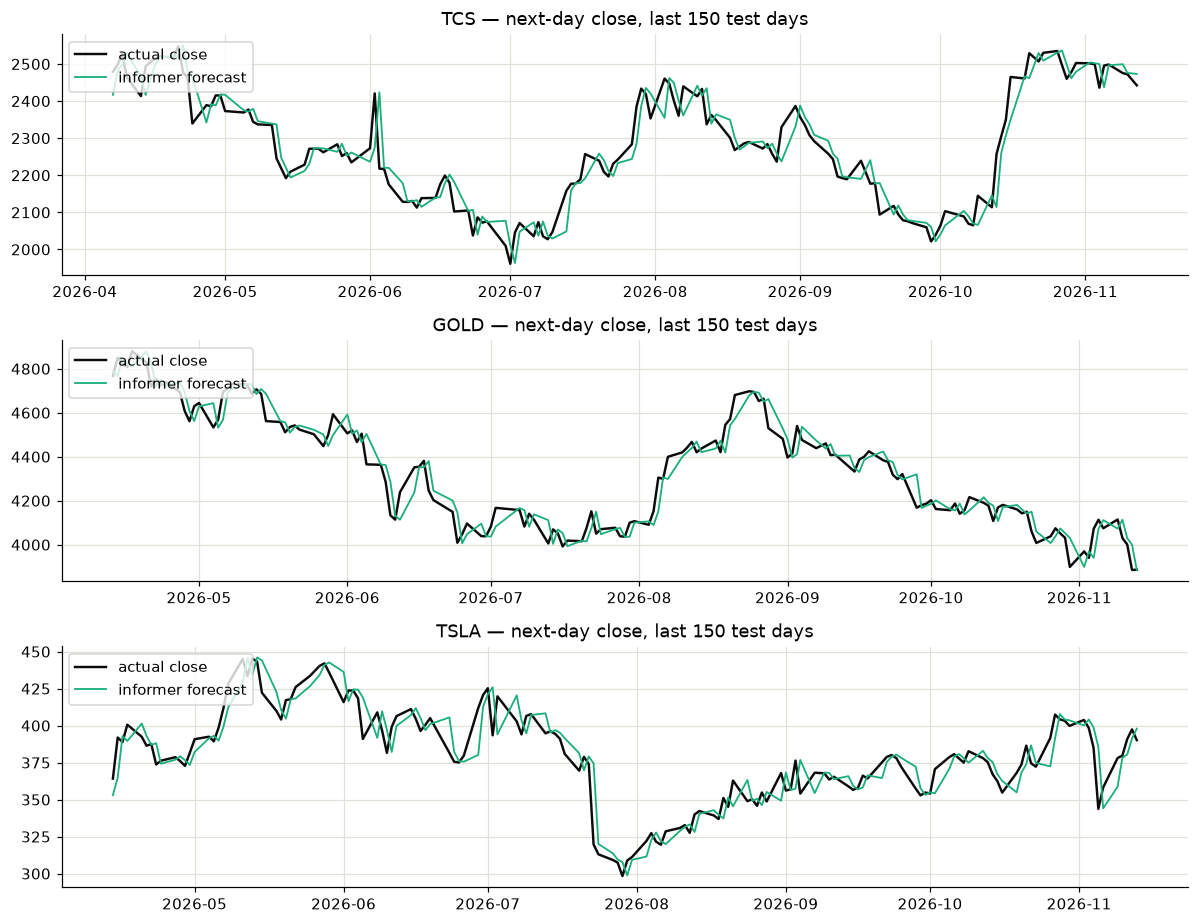

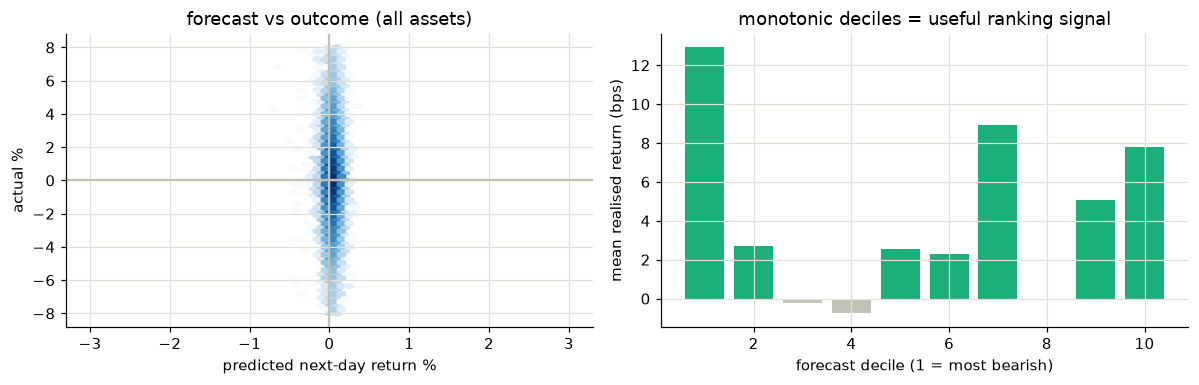

In [6]:
P = panel.np_
f = os.path.join(RESULTS, MODEL, "preds", f"ensemble_{MODEL}_full.npz")
if not os.path.exists(f):
    f = os.path.join(RESULTS, MODEL, "preds", f"final_{MODEL}_full_s0.npz")
z = np.load(f)
pred, te = z["pred"], z["ends"]
r_hat = pred[:, 0] * P["sigma"][te]
close_t, close_next = P["close"][te], P["y_close"][te, 0]
dates = pd.to_datetime(P["dates"][te], unit="D") + pd.offsets.BDay(1)
fig, axes = plt.subplots(3, 1, figsize=(11, 8.5))
for ax, t in zip(axes, ["TCS", "GOLD", "TSLA"]):
    m = P["tid"][te] == meta["tickers"].index(t)
    ax.plot(dates[m][-150:], close_next[m][-150:], color="#0b0b0b", lw=1.6, label="actual close")
    ax.plot(dates[m][-150:], (close_t * np.exp(r_hat))[m][-150:], color=COLORS[MODEL], lw=1.2, label=f"{MODEL} forecast")
    ax.set_title(f"{t} — next-day close, last 150 test days"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

y = P["y_ret"][te, 0]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hexbin(r_hat * 100, y * 100, gridsize=60, bins="log", cmap="Blues", extent=(-3, 3, -8, 8))
ax[0].axhline(0, color="#c3c2b7"); ax[0].axvline(0, color="#c3c2b7")
ax[0].set_xlabel("predicted next-day return %"); ax[0].set_ylabel("actual %"); ax[0].set_title("forecast vs outcome (all assets)")
# calibration: average realised return per forecast decile
q = pd.qcut(r_hat, 10, labels=False, duplicates="drop")
dec = pd.Series(y).groupby(q).mean() * 1e4
ax[1].bar(dec.index + 1, dec.values, color=[COLORS[MODEL] if v > 0 else "#c3c2b7" for v in dec.values])
ax[1].set_xlabel("forecast decile (1 = most bearish)"); ax[1].set_ylabel("mean realised return (bps)")
ax[1].set_title("monotonic deciles = useful ranking signal")
plt.tight_layout(); plt.show()

## 6 · Innovation: market-neutral target
Predicting *where the market goes* is a coin flip. Re-training on returns demeaned within (region, day) asks *which asset beats its peers* instead; checkpoints are chosen on validation correlation. A monotone staircase from Q1 to Q5 means the daily ranking is informative.

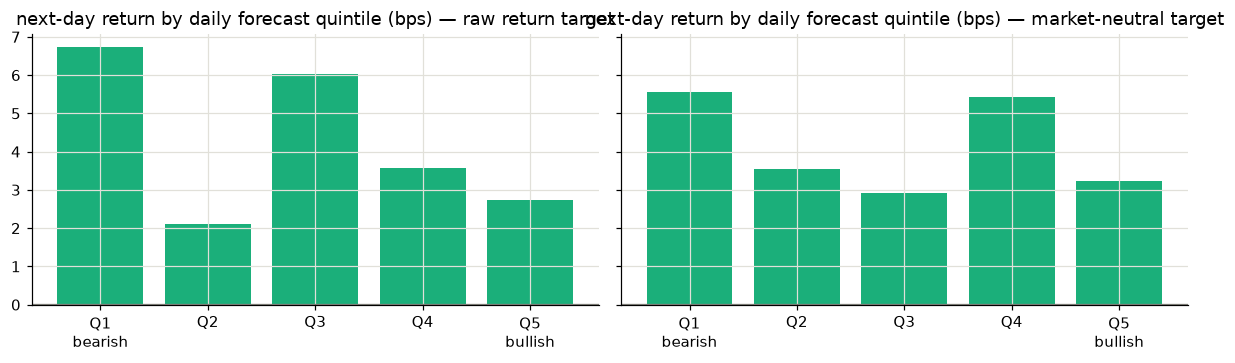

In [7]:
# Raw target vs market-neutral target: daily ranking quality on the test set
def quintiles(fname):
    z = np.load(os.path.join(RESULTS, MODEL, "preds", fname))
    te = z["ends"]
    df = pd.DataFrame({"d": P["dates"][te], "g": np.array(meta["region"])[P["tid"][te]], "p": z["pred"][:, 0], "y": P["y_ret"][te, 0]})
    df["q"] = df.groupby(["d", "g"]).p.rank(pct=True)
    df["Q"] = np.minimum((df.q * 5).astype(int), 4) + 1
    return df.groupby("Q").y.mean() * 1e4
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for a, (f, t) in zip(ax, [(f"ensemble_{MODEL}_full.npz", "raw return target"), (f"ensemble_xs_{MODEL}_full.npz", "market-neutral target")]):
    if os.path.exists(os.path.join(RESULTS, MODEL, "preds", f)):
        q = quintiles(f)
        a.bar(q.index, q.values, color=[COLORS[MODEL] if v > 0 else "#c3c2b7" for v in q.values])
    a.axhline(0, color="#898781"); a.set_xticks(range(1, 6), ["Q1\nbearish", "Q2", "Q3", "Q4", "Q5\nbullish"])
    a.set_title(f"next-day return by daily forecast quintile (bps) — {t}")
plt.tight_layout(); plt.show()

## 7 · Forecast cones: predicted range vs what actually happened
Every 5-day forecast gets an 80% and a 95% range. The width comes from how far prices moved in the 2022–23 validation period (in units of each asset's current volatility), so nothing from the test period is used. If the ranges are honest, the actual price should land inside the 80% band about 80% of the time.

test coverage: 80% band 79.9%  |  95% band 94.8%   (calibrated = 80 / 95)


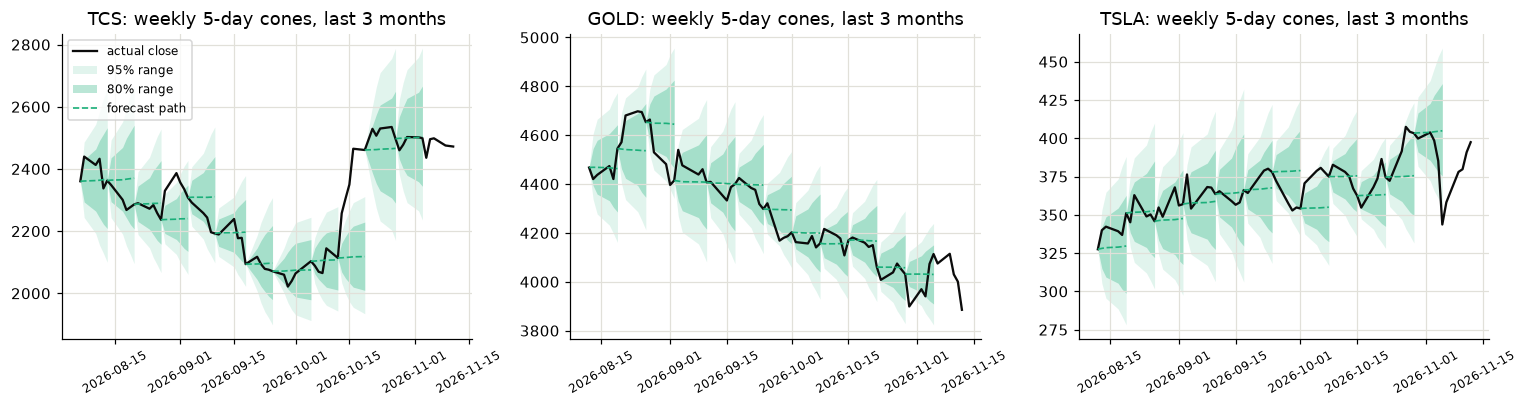

In [8]:
# Forecast cone: predicted 5-day path + calibrated 80% / 95% range, then the actual price over it
from stockdl.metrics import cone_quantiles, cone_coverage
va = panel.ends["val"]
Q = cone_quantiles(P["y_ret"][va].astype(float), P["sigma"][va].astype(float))   # band width from 2022-23 only
f = os.path.join(RESULTS, MODEL, "preds", f"ensemble_{MODEL}_full.npz")
z = np.load(f if os.path.exists(f) else f.replace("ensemble_", "final_").replace("_full.npz", "_full_s0.npz"))
te, r5 = z["ends"], z["pred"] * P["sigma"][z["ends"]][:, None]
cov = cone_coverage(r5, P["y_ret"][te].astype(float), P["sigma"][te].astype(float), Q)
print(f"test coverage: 80% band {cov[80]['all']:.1f}%  |  95% band {cov[95]['all']:.1f}%   (calibrated = 80 / 95)")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, t in zip(axes, ["TCS", "GOLD", "TSLA"]):
    rows_t = np.where(P["tid"][te] == meta["tickers"].index(t))[0]
    d0 = pd.to_datetime(P["dates"][te][rows_t], unit="D")
    c = P["close"][te][rows_t]
    lo_i = len(rows_t) - 6 - 60
    ax.plot(d0[lo_i:], c[lo_i:], color="#0b0b0b", lw=1.5, label="actual close")
    for k, j in enumerate(range(lo_i, len(rows_t) - 6, 5)):
        i = rows_t[j]
        cum = np.r_[0, np.cumsum(r5[i])]
        d = d0[j:j + 6]
        for L, a in [(95, .13), (80, .3)]:
            lo, hi = Q[L]
            ax.fill_between(d, c[j] * np.exp(cum + np.r_[0, lo] * P["sigma"][te][i]), c[j] * np.exp(cum + np.r_[0, hi] * P["sigma"][te][i]),
                            color=COLORS[MODEL], alpha=a, lw=0, label=f"{L}% range" if k == 0 else None)
        ax.plot(d, c[j] * np.exp(cum), color=COLORS[MODEL], ls="--", lw=1.1, label="forecast path" if k == 0 else None)
    ax.set_title(f"{t}: weekly 5-day cones, last 3 months"); ax.tick_params(axis="x", labelsize=8, rotation=30)
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

## 8 · Volatile vs non-volatile, shares vs commodities

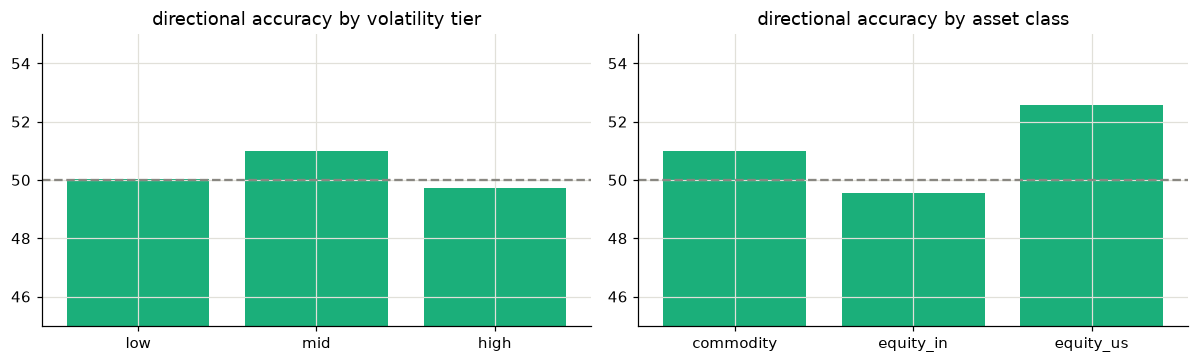

n    DA_%  R2_oos_%  MAPE_%  MAPE_naive_%
volatility tier low        12065.0  50.021    -0.074   1.044         1.042
                mid        11303.0  50.976     0.105   1.201         1.201
                high       11332.0  49.720    -0.024   1.909         1.908
asset class     commodity   4265.0  50.976    -0.011   1.734         1.734
                equity_in  24675.0  49.556    -0.043   1.298         1.297
                equity_us   5760.0  52.584     0.138   1.451         1.452

In [9]:
ens = [r for r in rows if r["phase"] == "ensemble" and r["features"] == "full"]
src = ens[0] if ens else [r for r in rows if r["phase"] == "final" and r["features"] == "full"][0]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
vt = pd.DataFrame(src["by_vol_tier"]).T.loc[["low", "mid", "high"]]
ac = pd.DataFrame(src["by_asset_class"]).T
ax[0].bar(vt.index, vt["DA_%"], color=COLORS[MODEL]); ax[0].axhline(50, color="#898781", ls="--")
ax[0].set_ylim(45, max(55, vt["DA_%"].max() + 1)); ax[0].set_title("directional accuracy by volatility tier")
ax[1].bar(ac.index, ac["DA_%"], color=COLORS[MODEL]); ax[1].axhline(50, color="#898781", ls="--")
ax[1].set_ylim(45, max(55, ac["DA_%"].max() + 1)); ax[1].set_title("directional accuracy by asset class")
plt.tight_layout(); plt.show()
display(pd.concat({"volatility tier": vt, "asset class": ac}).round(3))

## Takeaways
See the printed test table above. The project-level comparison of all three architectures is in the main `README.md`, the website and the report.